# Differential geometry 4: Gaussian curvature

*Learning path: differential geometry, part 4 of 7.* [Index](README.md) · Previous: [Surfaces](03-surfaces.ipynb) · Next: [Parallel transport](05-parallel-transport.ipynb)

Is a surface curved? From outside it is obvious, but in part 3 we saw that a cylinder has the same metric as a flat
sheet of paper. This notebook introduces the number that answers the question *from the inside*: the **Gaussian
curvature** $K$. You will learn

* what $K$ means geometrically, and what its sign tells you,
* Gauss's *Theorema Egregium*: $K$ can be computed from the metric alone,
* why you can fold a pizza slice to keep it from drooping, and why every flat map of the Earth is distorted,
* the Gauss–Bonnet theorem, which links curvature to the shape of a surface as a whole.

## 1. Curvature from outside

At a point on a surface, cut it with planes that contain the normal direction. Each cut is a curve with a curvature
(part 1). The largest and smallest of these are the *principal curvatures* $\kappa_1$, $\kappa_2$, and

$$K = \kappa_1 \kappa_2$$

* On a sphere of radius $r$ every cut is a great circle: $K = \frac1r\cdot\frac1r = 1/r^2 > 0$.
* On a cylinder one cut is a circle and the other a straight line: $K = \frac1r \cdot 0 = 0$.
* On a saddle the cuts bend in opposite directions: $K < 0$.

## 2. Curvature from inside: the Theorema Egregium

Gauss proved in 1827 that $K$ depends only on the metric, even though the definition above uses the surrounding
space. He called it his "remarkable theorem". `gausscurvature(g)` computes $K$ from a 2D metric:

In [1]:
sphere = [r*sin(theta)*cos(phi) r*sin(theta)*sin(phi) r*cos(theta)];
gausscurvature(inducedmetric(sphere, [theta phi]))

1.0/r^2.0

The cylinder and cone are flat, and so is the plane in polar coordinates:

In [2]:
cylinder = [cos(v) sin(v) h];
cone = [w*cos(v) w*sin(v) w];
gausscurvature(inducedmetric(cylinder, [h v]))
gausscurvature(inducedmetric(cone, [w v]))
gausscurvature(metric.generate(polar))

0.0
0.0
0.0

### The pizza theorem

A slice of pizza is (nearly) a flat surface, $K = 0$. Bending it keeps $K = 0$, so if you curve it across its width,
$\kappa_1 \ne 0$, the other principal curvature must be zero: the slice can no longer droop along its length. That is
why folding a slice keeps the tip up. The same idea makes corrugated cardboard and bent sheet metal stiff.

### Why every map of the Earth is wrong

A sphere has $K = 1/r^2 \ne 0$ and a flat map has $K = 0$. Since $K$ is determined by distances, no map can show all
distances on the Earth correctly, not even over a small region. Every projection (Mercator, Robinson, ...) is a
compromise.

## 3. Positive, negative and changing curvature

The saddle $z = u^2 - v^2$ has $K < 0$, strongest at the centre:

In [3]:
clear
gausscurvature(inducedmetric([u v u^2-v^2], [u v]))

(-4.0)/(4.0*u^2.0+4.0*v^2.0+1.0)^2.0

The helicoid, the spiral staircase from part 3, is negatively curved too:

In [4]:
helicoid = [w*cos(v) w*sin(v) v];
gausscurvature(inducedmetric(helicoid, [w v]))

(-1.0)/(w^2.0+1.0)^2.0

The hyperbolic plane from part 2 has $K = -1$ at every point. It is the negatively curved counterpart of the sphere:

In [5]:
gausscurvature(metric.generate(hyperbolic))

-1.0

On a torus the curvature changes sign: positive on the outside, like a sphere, and negative on the inside, like a
saddle.

In [6]:
torus = [(R+a*cos(u))*cos(v) (R+a*cos(u))*sin(v) a*sin(u)];
K = gausscurvature(inducedmetric(torus, [u v]))

cos(u)/(a*(R+a*cos(u)))

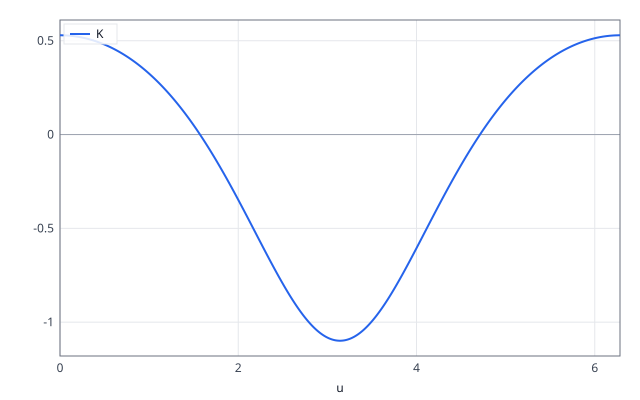

In [7]:
R = 2;
a = 0.7;
plot(K, u, 0, 2*pi)

$u = 0$ is the outer equator and $u = \pi$ the inner one. The curvature is zero on the top and bottom circles
($u = \pm\pi/2$), where the torus would rest on a table.

## 4. Gauss–Bonnet: curvature adds up to topology

Here is the most surprising fact in this notebook. Add up the curvature over a whole closed surface,
$\iint K\,dA$, and you get $2\pi\chi$, where $\chi$ is a whole number that only depends on how many holes the surface
has: $\chi = 2$ for a sphere, $0$ for a torus. Squash or stretch the surface as much as you like; the total does not
change.

Try it with ellipsoids $\big(a\sin\theta\cos\phi,\; a\sin\theta\sin\phi,\; c\cos\theta\big)$:

In [8]:
clear
ellipsoid = [a*sin(theta)*cos(phi) a*sin(theta)*sin(phi) c*cos(theta)];
e = inducedmetric(ellipsoid, [theta phi])
gausscurvature(e)

$$ds^2 = \left(a^{2} \cos^{2}\left(\theta\right) + c^{2} \sin^{2}\left(\theta\right)\right)\, d\theta^2 + \sin^{2}\left(\theta\right) a^{2}\, d\phi^2$$

c^2.0/(a^2.0-1.0*a^2.0*sin(theta)^2.0+c^2.0*sin(theta)^2.0)^2.0

The area element is $\sqrt{\det g} = a\sin\theta\sqrt{a^2\cos^2\theta + c^2\sin^2\theta}$, so after integrating $\phi$
the total curvature is $\int_0^\pi 2\pi\,a c^2\sin\theta\,/\,(a^2\cos^2\theta + c^2\sin^2\theta)^{3/2}\,d\theta$. For a
flattened, a round and an elongated ellipsoid:

In [9]:
a = 1;
c = 0.3;
odesolve([2*pi*a*c^2*sin(theta)/(a^2*cos(theta)^2 + c^2*sin(theta)^2)^(3/2)], [total], theta, [0], 0, pi)
c = 1;
odesolve([2*pi*a*c^2*sin(theta)/(a^2*cos(theta)^2 + c^2*sin(theta)^2)^(3/2)], [total], theta, [0], 0, pi)
c = 3;
odesolve([2*pi*a*c^2*sin(theta)/(a^2*cos(theta)^2 + c^2*sin(theta)^2)^(3/2)], [total], theta, [0], 0, pi)
eval(4*pi)

12.566370614357888
12.56637061436189
12.56637061436474
12.566370614359172

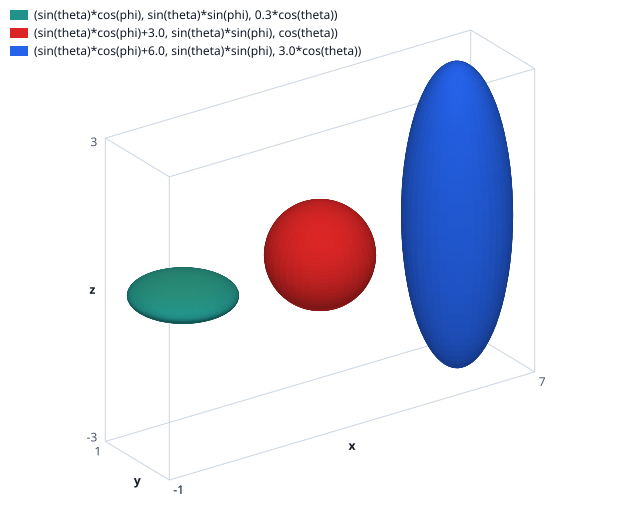

In [10]:
flat = surface(sin(theta)*cos(phi), sin(theta)*sin(phi), 0.3*cos(theta), theta, 0, pi, phi, 0, 2*pi);
round = surface(sin(theta)*cos(phi) + 3, sin(theta)*sin(phi), cos(theta), theta, 0, pi, phi, 0, 2*pi);
long = surface(sin(theta)*cos(phi) + 6, sin(theta)*sin(phi), 3*cos(theta), theta, 0, pi, phi, 0, 2*pi);
show(flat, round, long)

All three give $4\pi$: the flattened ellipsoid packs its curvature into the sharp rim, the elongated one into its
tips. For the torus, $K\sqrt{\det g} = \cos u$, and $\int_0^{2\pi}\cos u\,du = 0$: the positive curvature outside
exactly cancels the negative curvature inside.

## Summary

* $K = \kappa_1\kappa_2$; positive like a sphere, zero like a cylinder, negative like a saddle.
* `gausscurvature(g)` computes it from the metric alone (Theorema Egregium).
* Bending without stretching keeps $K$; that explains folded pizza and distorted maps.
* Gauss–Bonnet: $\iint K\,dA = 2\pi\chi$ depends only on the topology.

**Try it:** compute the curvature of the paraboloid `[u v u^2+v^2]` and of the Enneper surface from part 3.

Next: [Parallel transport](05-parallel-transport.ipynb), where curvature shows up as a vector that comes back turned.